# Synthetic shapes

Runs the synthetic experiment, saves every run under `results_synthetic/`, lists the per-run numbers and
draws the calibrated 90% regions of five methods against the true region.

Each run calls `synthetic.py`, so it is the same as a run from the command line. Finished runs are not
repeated: their saved result is shown instead, so the notebook can be re-run at any time.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import pandas as pd

REPO = Path.cwd() if (Path.cwd() / "synthetic.py").exists() else Path.cwd().parent
OUT = REPO / "results_synthetic"
sys.path.insert(0, str(REPO))


def run(shape, method, seeds):
    """python synthetic.py for the seeds without a result yet; prints every run's result."""
    todo = [s for s in seeds if not (OUT / shape / method / f"seed{s}" / "row.json").exists()]
    if todo:
        cmd = ["synthetic.py", "--shape", shape, "--method", method, "--seeds", *map(str, todo),
               "--output-dir", str(OUT.relative_to(REPO))]
        print("$ python", " ".join(cmd))
        with subprocess.Popen([sys.executable, "-u", *cmd], cwd=REPO, stdout=subprocess.PIPE,
                              stderr=subprocess.STDOUT, text=True) as p:
            for line in p.stdout:
                if line.startswith("RESULT"):
                    print(line, end="")
        if p.returncode:
            raise RuntimeError(f"{shape} / {method} failed")
    for s in seeds:
        if s not in todo:
            r = json.loads((OUT / shape / method / f"seed{s}" / "row.json").read_text())
            print(f"RESULT {shape} {method} seed={s} coverage={r['coverage']:.4f} "
                  f"V/V*={r['v_over_v_star']:.4f} IoU={r['iou']:.4f}  (saved)")

## Settings

`SEEDS = None` runs one seed per shape, the seeds of the figure. Set `SEEDS = [42, 43, 44, 45, 46]` for all
five seeds of the experiment.

In [2]:
SHAPES = ["ellipse", "rectangle", "triangle", "trapezoid"]
METHODS = ["absolute_residual", "empirical_copula", "global_ellipsoid", "local_ellipsoid", "mvcs", "spline", "spline_l1",
           "icnn"]
FIGURE_SEEDS = {"ellipse": 43, "rectangle": 43, "triangle": 43, "trapezoid": 44}
SEEDS = None

## 1. Run every method on every shape

The spline is tuned first on each (shape, seed); its choice is saved in `results_synthetic/tuning/` and the
$\ell_1$ spline (`spline_l1`) reuses it.

In [3]:
for shape in SHAPES:
    for method in METHODS:
        run(shape, method, SEEDS or [FIGURE_SEEDS[shape]])

RESULT ellipse absolute_residual seed=43 coverage=0.8800 V/V*=2.6850 IoU=0.3478  (saved)
RESULT ellipse empirical_copula seed=43 coverage=0.8910 V/V*=1.2459 IoU=0.7798  (saved)
RESULT ellipse global_ellipsoid seed=43 coverage=0.8800 V/V*=1.0490 IoU=0.9536  (saved)
RESULT ellipse local_ellipsoid seed=43 coverage=0.8810 V/V*=1.1593 IoU=0.8698  (saved)
RESULT ellipse mvcs seed=43 coverage=0.8780 V/V*=1.0420 IoU=0.9605  (saved)
RESULT ellipse spline seed=43 coverage=0.8840 V/V*=1.2287 IoU=0.7993  (saved)
RESULT ellipse icnn seed=43 coverage=0.8790 V/V*=1.0777 IoU=0.9227  (saved)
RESULT rectangle absolute_residual seed=43 coverage=0.8890 V/V*=1.8185 IoU=0.5215  (saved)
RESULT rectangle empirical_copula seed=43 coverage=0.8840 V/V*=1.7236 IoU=0.5528  (saved)
RESULT rectangle global_ellipsoid seed=43 coverage=0.8790 V/V*=1.3009 IoU=0.7452  (saved)
RESULT rectangle local_ellipsoid seed=43 coverage=0.8890 V/V*=1.3523 IoU=0.7144  (saved)
RESULT rectangle mvcs seed=43 coverage=0.8850 V/V*=1.2991 

## 2. Results of every run

Test coverage, V/V\* (mean region area over the area of the true region) and IoU with the true region.

In [4]:
rows = [json.loads(f.read_text()) for f in sorted(OUT.glob("*/*/seed*/row.json"))]
runs = pd.DataFrame(rows)[["shape", "method", "seed", "coverage", "v_over_v_star", "iou"]]
runs = runs.set_index(["shape", "method", "seed"]).sort_index().round(4)
runs

coverage  v_over_v_star     iou
shape     method            seed                                 
ellipse   absolute_residual 43       0.880         2.6850  0.3478
          empirical_copula  43       0.891         1.2459  0.7798
          global_ellipsoid  43       0.880         1.0490  0.9536
          icnn              43       0.879         1.0777  0.9227
          local_ellipsoid   43       0.881         1.1593  0.8698
          mvcs              43       0.878         1.0420  0.9605
          spline            43       0.884         1.2287  0.7993
rectangle absolute_residual 43       0.889         1.8185  0.5215
          empirical_copula  43       0.884         1.7236  0.5528
          global_ellipsoid  43       0.879         1.3009  0.7452
          icnn              43       0.891         1.1467  0.8577
          local_ellipsoid   43       0.889         1.3523  0.7144
          mvcs              43       0.885         1.2991  0.7512
          spline            43       0.887         1.1327  0.8829
trapezoid absolute_residual 44       0.914         1.6357  0.5690
          empirical_copula  44       0.912         1.6289  0.5680
          global_ellipsoid  44       0.909         1.4129  0.6684
          icnn              44       0.900         1.1589  0.8557
          local_ellipsoid   44       0.906         1.4320  0.6668
          mvcs              44       0.908         1.3872  0.6861
          spline            44       0.905         1.3256  0.7176
triangle  absolute_residual 43       0.894         2.0873  0.4396
          empirical_copula  43       0.881         1.8483  0.5013
          global_ellipsoid  43       0.877         1.6313  0.5705
          icnn              43       0.878         1.1251  0.8837
          local_ellipsoid   43       0.873         1.6573  0.5651
          mvcs              43       0.875         1.6404  0.5663
          spline            43       0.878         1.5943  0.5911

## 3. Figure

The calibrated 90% region of each method at x = (0, 0) for the figure seeds, over the test residuals and the
true region. Saved as `results_synthetic/synthetic_regions.pdf`.

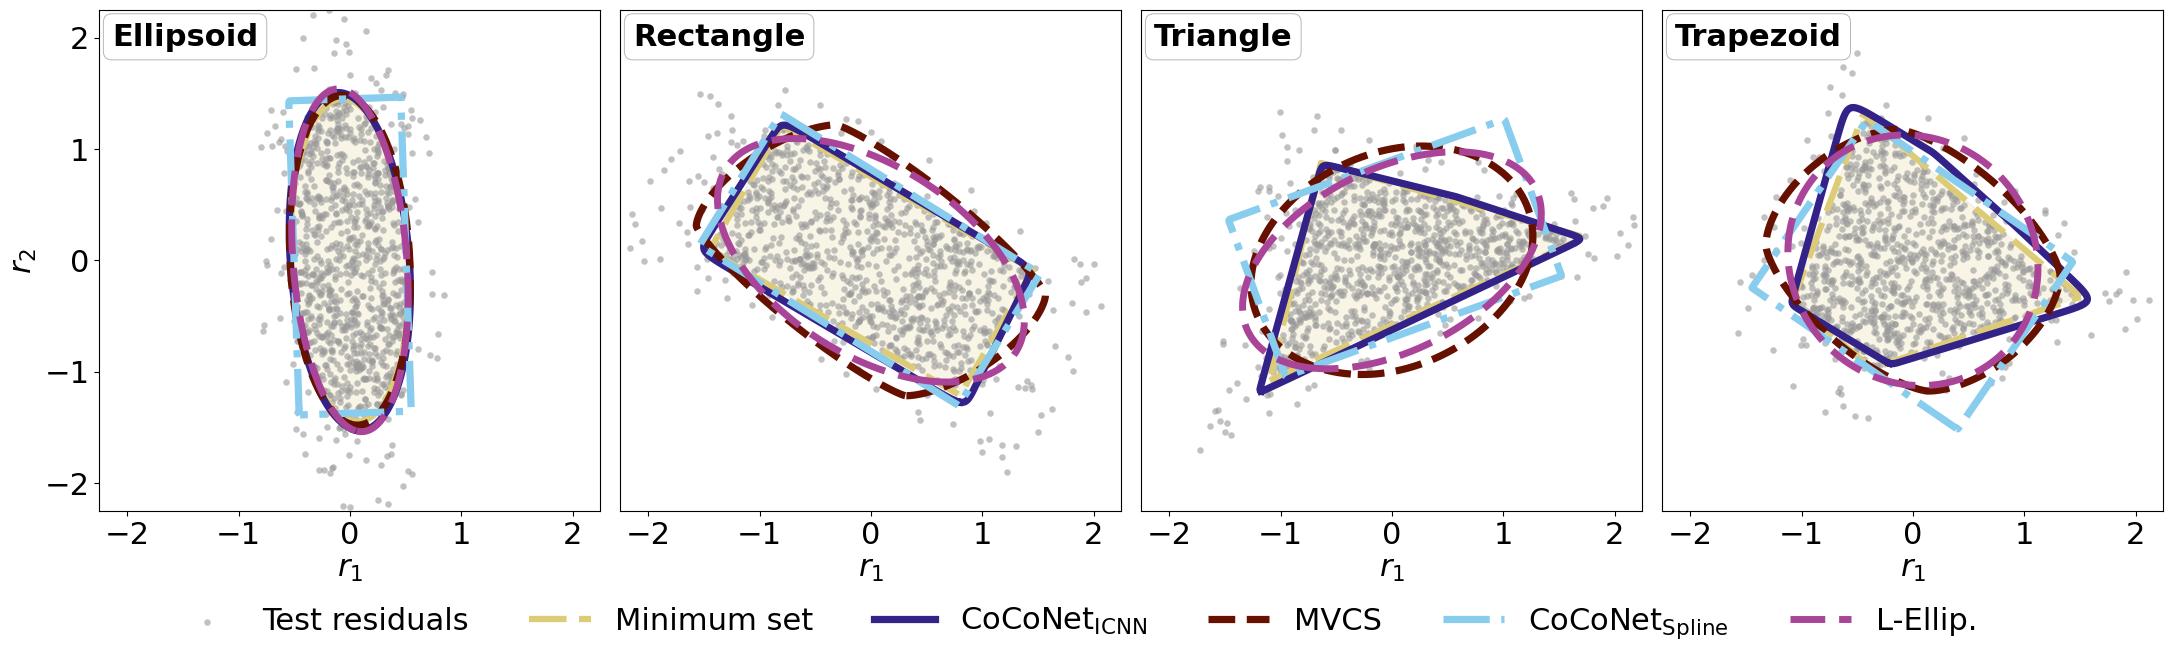

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
from plot_synthetic import plot

fig = plot(OUT, [FIGURE_SEEDS[s] for s in SHAPES])
fig.savefig(OUT / "synthetic_regions.pdf", bbox_inches="tight")
plt.show()